# Name That LLM: 짧은 지문으로 작성 모델 식별하기

## 1. 풀려는 문제

짧은 영어 지문 하나를 보고 **18개 LLM 중 어느 모델이 썼는지** 맞히는 18-클래스 텍스트 분류 문제입니다.

- **입력**: 지문 1개 (단어 36~274개, 중앙값 약 100개)
- **출력**: 모델 이름 1개 (GPT 5개, Gemini 4개, Claude 5개, Qwen·GLM·Kimi 4개)
- **지표**: balanced accuracy (클래스별 recall의 평균). 무작위로 찍으면 1/18 ≈ 0.056입니다.
- **어려운 점**: 테스트 지문의 프롬프트(주제)는 train에 한 번도 나오지 않습니다. 그래서 *무엇을* 썼는지가 아니라 **어떻게** 썼는지(문체)를 배워야 합니다. 같은 연구소 모델끼리는 문체가 비슷해서 서로 많이 헷갈립니다.



## 2. 학습 데이터

| 파일 | 크기 | 컬럼 | 설명 |
|---|---|---|---|
| `train.csv` | 2,699행 | `id`, `prompt_id`, `text`, `model` | 프롬프트 150개 × 모델 18개. 프롬프트마다 18개 모델이 한 번씩 답했습니다 (1개 프롬프트만 17개). |
| `test.csv` | 3행 (제출 시 숨겨진 약 4,000행) | `id`, `text` | `prompt_id`와 정답이 없습니다. |
| `ntl_open_pool.parquet` (외부, 선택) | 라벨당 최대 2,500개 사용 | `text`, `model`, `match_weight` | 같은 18개 모델이 쓴 추가 지문입니다. |

모델당 train 지문이 약 150개뿐이라 데이터가 적습니다. Open Pool이 이 부족을 메웁니다. `match_weight`는 풀의 문장부호 분포를 대회 지문과 비슷하게 맞추는 표본 추출 가중치입니다.


## 3. Model Architecture

Two models with very different inductive biases are trained separately, and their calibrated log-probabilities are blended.

```
                               text (one passage)
                                       |
              +------------------------+-------------------------+
              |                                                  |
              v                                                  v
 [A] n-gram branch (CPU)                          [B] LoRA branch (GPU)
 4 views of the same text:                        Qwen3-4B-Base tokenizer
   char  : raw text, char 3-5-grams                 ids [B,T], T <= 384
   word  : raw text, word 1-2-grams                        |
   shape : Hello -> X, the -> x                   token embedding   [B,T,2560]
   func  : keep function words only                        |
           (the _ of _)                           18 x Qwen3 decoder block (frozen)
              |                                     + LoRA (r=16) on q/k/v/o
   TF-IDF per view, weighted, hstack                       |
   X [N, <=510k] (sparse)                         tap hidden states at depths
              |                                     2, 4, 6, 9, 12, 15, 18
   LinearSVC, one-vs-rest                         masked mean-pool + LayerNorm each
   S [N,18]                                       concat -> [B,17920]
              |                                            |
              |                                   linear head -> logits [B,18]
              |                                            |
   LP_A = log_softmax(S / T_A)                    LP_B = log_softmax(logits / T_B)
              |                                            |
              +-------------------+------------------------+
                                  |
                     LP = w * LP_B + (1 - w) * LP_A             [N,18]
                                  |
                prompt centering inside topic clusters           [N,18]
                                  |
                          argmax over k -> predicted model
```

- **A. n-gram branch** captures surface habits: punctuation, spelling, sentence rhythm. The `shape` and `func` views delete topic words, so they are less tempted to memorize the prompt. Fast, deterministic baseline.
- **B. LoRA branch** reuses the stylistic representations a pretrained LM already has. Style information survives better in early/middle layers than in the last one, so only the first 18 of 36 layers are kept and several depths are pooled together. LoRA is implemented by hand (no `peft`) so the notebook runs offline. Trained on the Open Pool first (Stage 1), then fine-tuned on `train` (Stage 2).
- **Blending**: `w` and the two temperatures are chosen on a held-out set of prompts that LoRA never saw. Without a GPU or Qwen3 weights, branch B is skipped (`w = 0`).
- **Prompt centering**: passages that answer the same prompt share a topic. Subtracting the cluster mean removes part of the topic signal and leaves the per-model style difference.

### 3.1 Notation

Einsum index letters are used consistently below. Shapes are written as `[...]`.

| Index | Meaning | Value |
|---|---|---|
| `n` | passages in an n-gram matrix | any `N` |
| `b` | passages in a GPU batch | 16 for training, 32 for inference (8 / 16 on Colab L4) |
| `t`, `s` | query / key token position | `T <= 384` (`max_len`) |
| `d` | Qwen3 hidden size | `D = 2560` |
| `h` | query heads | `H = 32` |
| `g` | key/value heads (grouped-query attention) | `G = 8` |
| `m` | query heads per KV head, `h = g*4 + m` | `M = 4` |
| `e` | head dimension | `E = 128` |
| `f` | MLP intermediate size | `F = 9728` |
| `r` | LoRA rank | `R = 16` |
| `l` | pooled depths | `L = 7` |
| `c` | concatenated pooled feature, `L*D` | `C = 17920` |
| `k` | classes (LLM labels) | `K = 18` |
| `p` | sparse n-gram features | `P <= 510,000` |
| `v` | vocabulary | `V = 151,936` |

### 3.2 Branch A: multi-view TF-IDF + LinearSVC

**Views.** Each passage is rewritten four ways before vectorizing.

| View | Text transform | Example: `The Cat sat, 42 times.` | Analyzer | n-gram range | max features `P_v` | View weight `w_v` |
|---|---|---|---|---|---|---|
| `char` | none | `The Cat sat, 42 times.` | characters | 3-5 | 250,000 | 1.0 |
| `word` | none | tokens `\w+` or single punctuation | words | 1-2 | 150,000 | 0.7 |
| `shape` | each letter run -> `X` (capitalized) or `x` | `X X x, 42 x.` | characters | 2-6 | 60,000 | 0.5 |
| `func` | keep function words and punctuation, others -> `_` | `the _ _ , _ _ .` | whitespace tokens | 1-3 | 50,000 | 0.5 |

All vectorizers use `lowercase=False`, `min_df=2`, `sublinear_tf=True`, and the default L2 row normalization. They are fit on an unlabeled Open Pool sample (up to 2,500 passages per label), never on validation prompts.

**Layers.**

| # | Layer | Operation | Input | Output | Activation |
|---|---|---|---|---|---|
| A1 | TF-IDF (per view `v`) | `x_v[n,p] = w_v * l2norm_p( (1 + log tf[n,p]) * idf[p] )` | `N` strings | `[N, P_v]` sparse | none (log-scaled term frequency) |
| A2 | Concatenate views | `X[n,p] = hstack_v x_v[n,p]` | 4 x `[N, P_v]` | `[N, P]`, `P = sum_v P_v <= 510,000` | none |
| A3 | LinearSVC, one-vs-rest | `S = einsum('np,kp->nk', X, W) + b[k]` | `[N, P]` | `[N, 18]` | none (linear margin scores) |
| A4 | Temperature calibration | `LP_A[n,k] = log_softmax_k( S[n,k] / T_A )` | `[N, 18]` | `[N, 18]` | log-softmax |

- Parameters: `W` is `[18, P]`, `b` is `[18]`, so up to about 9.2M weights.
- Training objective: 18 independent binary problems, squared hinge loss with L2 penalty, `C = 0.1`. Sample weight 1.0 for both Open Pool and `train` rows.
- `T_A` is picked from `{0.05, ..., 3}` by minimizing out-of-fold negative log-likelihood.

### 3.3 Branch B: Qwen3-4B-Base trunk + LoRA + multi-depth pooling head

Base model config (Qwen3-4B-Base): 36 decoder layers, `D = 2560`, 32 query heads, 8 KV heads, head dim 128, MLP size 9728, RMSNorm `eps = 1e-6`, RoPE `theta = 1,000,000`, no attention bias.
Changes made in this notebook:

- Only the first `keep_layers = 18` decoder blocks are loaded. Blocks 19-36 and the LM head are dropped (`AutoModel`, not `AutoModelForCausalLM`).
- The final RMSNorm is replaced by `nn.Identity()`, so tapped hidden states are the raw residual stream.
- All original weights are frozen. LoRA adapters are added to `q_proj`, `k_proj`, `v_proj`, `o_proj` in every kept block.
- Trunk weights are stored in fp16 on T4 (bf16 on Ampere or newer) and run under autocast. LoRA, LayerNorm, and head weights are fp32. Pooling is done in fp32.

#### B0. Tokenization

| # | Step | Operation | Input | Output |
|---|---|---|---|---|
| B0 | Tokenize | Qwen3 BPE tokenizer, `add_special_tokens=False`, truncate to 384 tokens | `B` strings | `ids [B, T]` int64 |
| | Pad + mask | right padding with `pad_token` to the longest sequence in the batch | | `ids [B, T]`, `mask [B, T]` in {0, 1} |

Training batches are length-bucketed (sorted inside chunks of 50 batches, then shuffled) to reduce padding.

#### B1. Embedding

| # | Layer | Operation | Input | Output | Activation |
|---|---|---|---|---|---|
| B1 | Token embedding (frozen) | `h0[b,t,d] = Emb[ids[b,t], d]`, `Emb` is `[V, D]` | `[B, T]` | `[B, T, 2560]` | none |

There is no absolute position embedding. Position enters only through RoPE inside attention.

#### B2. Decoder block, repeated for depth 1..18 (pre-norm)

Input `x = h_{depth-1}` with shape `[B, T, 2560]`. Every projection marked "+ LoRA" is `W x + 2.0 * B(A(x))` (see B3).

```
x [B,T,2560] -----------------------------------+
   |                                            |
 RMSNorm (input_layernorm)                      |
   |                                            |
 q_proj+LoRA   k_proj+LoRA   v_proj+LoRA        |
 [B,T,32,128]  [B,T,8,128]   [B,T,8,128]        |
   |             |             |                |
 q_norm        k_norm          |                |
 RoPE          RoPE            |                |
   +------+------+             |                |
          |                    |                |
 GQA scores [B,8,4,T,T]        |                |
 causal mask, softmax over s   |                |
          +---------+----------+                |
                    |                           |
           weighted sum [B,T,32,128]            |
                    |                           |
           o_proj+LoRA [B,T,2560]               |
                    |                           |
                   (+) <------------------------+
                    |
                    +---------------------------+
                    |                           |
          RMSNorm (post_attention_layernorm)    |
                    |                           |
     gate_proj [B,T,9728]   up_proj [B,T,9728]  |
          SiLU                  |               |
            +------- (*) -------+               |
                      |                         |
             down_proj [B,T,2560]               |
                      |                         |
                     (+) <----------------------+
                      |
                  h_depth [B,T,2560]
```

| # | Layer | Operation (einsum) | Input | Output | Activation |
|---|---|---|---|---|---|
| a | RMSNorm (`input_layernorm`) | `u = x * rsqrt(mean_d(x^2) + 1e-6) * gamma[d]` | `[B,T,2560]` | `[B,T,2560]` | none |
| b | Query projection + LoRA | `q = einsum('btd,dhe->bthe', u, Wq)`, `Wq` is `[2560, 32, 128]` | `[B,T,2560]` | `[B,T,32,128]` | none |
| c | Key projection + LoRA | `k = einsum('btd,dge->btge', u, Wk)`, `Wk` is `[2560, 8, 128]` | `[B,T,2560]` | `[B,T,8,128]` | none |
| d | Value projection + LoRA | `v = einsum('btd,dge->btge', u, Wv)`, `Wv` is `[2560, 8, 128]` | `[B,T,2560]` | `[B,T,8,128]` | none |
| e | QK-norm (`q_norm`, `k_norm`) | RMSNorm over `e` for each head, `gamma[e]` of size 128 | `[B,T,32,128]`, `[B,T,8,128]` | same | none |
| f | RoPE | rotate each pair `(e_2i, e_2i+1)` of `q` and `k` by angle `t * theta^(-2i/128)` | same | same | none (rotation) |
| g | Attention scores (GQA) | reshape `q` to `[B,T,8,4,128]`; `a = einsum('btgme,bsge->bgmts', q, k) / sqrt(128)`; set `a = -inf` where `s > t` | `[B,T,8,4,128]`, `[B,T,8,128]` | `[B,8,4,T,T]` | none |
| h | Attention weights | `p = softmax_s(a)` | `[B,8,4,T,T]` | `[B,8,4,T,T]` | **softmax** |
| i | Weighted sum of values | `o = einsum('bgmts,bsge->btgme', p, v)`, reshape to `[B,T,32,128]` | `[B,8,4,T,T]`, `[B,T,8,128]` | `[B,T,32,128]` | none |
| j | Output projection + LoRA | `y = einsum('bthe,hed->btd', o, Wo)`, `Wo` is `[32, 128, 2560]` | `[B,T,32,128]` | `[B,T,2560]` | none |
| k | Residual add | `x2 = x + y` | `[B,T,2560]` x 2 | `[B,T,2560]` | none |
| l | RMSNorm (`post_attention_layernorm`) | `u2 = x2 * rsqrt(mean_d(x2^2) + 1e-6) * gamma2[d]` | `[B,T,2560]` | `[B,T,2560]` | none |
| m | Gate and up projections | `g1 = einsum('btd,df->btf', u2, Wgate)`, `g2 = einsum('btd,df->btf', u2, Wup)` | `[B,T,2560]` | `[B,T,9728]` x 2 | none |
| n | Gated activation (SwiGLU) | `z = SiLU(g1) * g2`, with `SiLU(x) = x * sigmoid(x)` | `[B,T,9728]` x 2 | `[B,T,9728]` | **SiLU** |
| o | Down projection | `y2 = einsum('btf,fd->btd', z, Wdown)` | `[B,T,9728]` | `[B,T,2560]` | none |
| p | Residual add | `h_depth = x2 + y2` | `[B,T,2560]` x 2 | `[B,T,2560]` | none |

Notes:
- Attention dropout is 0 in Qwen3. Each KV head `g` is shared by the 4 query heads `m` in its group.
- Padding is on the right and attention is causal, so real tokens never attend to padding. Outputs at padded positions are computed but removed by the pooling mask in B4.
- Frozen parameters per block: about 100.9M (attention 26.2M + MLP 74.7M + norms). Frozen trunk total: 389.0M (embedding) + 18 x 100.9M = about 2.21B.

#### B3. LoRA adapter (inside b, c, d, j)

For a frozen linear layer `W` of shape `[D_out, D_in]`:

$$ y = W x + \frac{\alpha}{r} \, B \, A \, \mathrm{dropout}(x), \qquad \frac{\alpha}{r} = \frac{32}{16} = 2.0 $$

| # | Step | Operation (einsum) | Input | Output | Activation |
|---|---|---|---|---|---|
| L1 | Frozen path | `y0 = einsum('bti,oi->bto', x, W)` | `[B,T,D_in]` | `[B,T,D_out]` | none |
| L2 | Dropout | `x' = dropout(x, p=0.05)` (training only) | `[B,T,D_in]` | `[B,T,D_in]` | none |
| L3 | Down-projection `A` | `z = einsum('bti,ri->btr', x', A)`, `A` is `[16, D_in]`, Kaiming-uniform init | `[B,T,D_in]` | `[B,T,16]` | none |
| L4 | Up-projection `B` | `delta = einsum('btr,or->bto', z, B)`, `B` is `[D_out, 16]`, zero init | `[B,T,16]` | `[B,T,D_out]` | none |
| L5 | Merge | `y = y0 + 2.0 * delta` | `[B,T,D_out]` x 2 | `[B,T,D_out]` | none |

There is no nonlinearity between `A` and `B`: the update is a purely linear rank-16 correction. Because `B` starts at zero, the model at step 0 is exactly the pretrained Qwen3.

| Target | `D_in` | `D_out` | LoRA params `16*(D_in + D_out)` |
|---|---|---|---|
| `q_proj` | 2560 | 4096 (32 x 128) | 106,496 |
| `k_proj` | 2560 | 1024 (8 x 128) | 57,344 |
| `v_proj` | 2560 | 1024 (8 x 128) | 57,344 |
| `o_proj` | 4096 | 2560 | 106,496 |
| per block | | | 327,680 |
| 18 blocks | | | **5,898,240** |

#### B4. Multi-depth pooling head

`hidden_states[0]` is the embedding output and `hidden_states[i]` is the output of block `i`. The head taps `L = 7` depths `i in {2, 4, 6, 9, 12, 15, 18}`. For each tap `l`:

| # | Layer | Operation (einsum) | Input | Output | Activation |
|---|---|---|---|---|---|
| H1 | Masked mean pooling (fp32) | `pooled_l = einsum('btd,bt->bd', h_l, mask) / max(1, einsum('bt->b', mask))` | `[B,T,2560]`, `[B,T]` | `[B,2560]` | none |
| H2 | LayerNorm (one per tap) | `n_l = (pooled_l - mean_d) / sqrt(var_d + 1e-5) * gamma_l[d] + beta_l[d]` | `[B,2560]` | `[B,2560]` | none |
| H3 | Concatenate taps | `z = concat_l n_l` | 7 x `[B,2560]` | `[B,17920]` | none |
| H4 | Dropout | `z = dropout(z, p=0.1)` (training only) | `[B,17920]` | `[B,17920]` | none |
| H5 | Linear classifier | `logits = einsum('bc,kc->bk', z, Whead) + bhead[k]`, `Whead` is `[18, 17920]` | `[B,17920]` | `[B,18]` | none |
| H6 | Output | train: cross-entropy over `softmax_k(logits)` with label smoothing 0.05; inference: `LP_B = log_softmax_k(logits / T_B)` | `[B,18]` | loss scalar / `[B,18]` | **softmax** (inside the loss) / log-softmax |

The per-tap LayerNorm puts every depth on the same scale before concatenation. Without it, deeper residual streams (which have much larger norms) would dominate the head.

#### B5. Parameter count and training

| Part | Parameters | Trainable |
|---|---|---|
| Embedding + 18 decoder blocks | about 2.21B | no |
| LoRA on q/k/v/o (18 blocks) | 5,898,240 | yes |
| 7 LayerNorms (`gamma`, `beta`) | 35,840 | yes |
| Linear head | 322,578 | yes |
| **Total trainable** | **6,256,658** (about 0.28% of the trunk) | |

| | Stage 1 | Stage 2 |
|---|---|---|
| Data | Open Pool, up to 2,500 per label (`match_weight` sampling) | `train` minus fold-0 prompts |
| Epochs / LR | 1 / 2e-4 | 2 / 5e-5 |
| Time budget | 3.0 h | 1.0 h |

Shared settings: AdamW (weight decay 0.01), head and LayerNorm LR x5, 5% linear warmup then cosine decay, gradient clipping at 1.0, fp16 `GradScaler` on T4, steps with a non-finite loss are skipped.

### 3.4 Blending and prompt centering

| # | Step | Operation | Input | Output | Activation |
|---|---|---|---|---|---|
| C1 | Weighted blend | `LP = w * LP_B + (1 - w) * LP_A`, `w in {0, 0.1, ..., 1}` chosen by holdout balanced accuracy | `[N,18]` x 2 | `[N,18]` | none |
| C2 | Topic clustering (test only) | TF-IDF without English stop words, then agglomerative clustering (cosine distance, average linkage, threshold 0.9) | `N` strings | cluster id per passage | none |
| C3 | Centering | for each cluster `c` with 2 to 18 members: `LP'[i,k] = LP[i,k] - 0.5 * einsum('jk->k', LP[c]) / n_c` for `i in c`; other passages unchanged | `[N,18]` | `[N,18]` | none |
| C4 | Prediction | `pred[n] = argmax_k LP'[n,k]` | `[N,18]` | `[N]` label ids | argmax |


## 4. 파이프라인

| 노트북 섹션 | 하는 일 | 결과물 | 환경 |
|---|---|---|---|
| 1. 데이터 | train, test, Open Pool을 읽고, train과 겹치는 풀 지문을 뺍니다. | `train`, `test`, `pool` | CPU |
| 2. 검증 | `prompt_id` 단위로 묶어 5-fold를 나눕니다. 테스트처럼 처음 보는 주제로 평가하기 위해서입니다. | `cv_folds` | CPU |
| 3. n-gram 모델 | 4뷰 TF-IDF + LinearSVC를 학습해 OOF 점수와 test 점수를 만듭니다. | `oof_ng`, `ng_test` | CPU |
| 4. LoRA 분류기 | fold 0을 홀드아웃으로 빼고 Stage 1 → Stage 2 순서로 학습합니다. 단계마다 시간 예산이 있습니다. | `holdout_logits`, `lora_test`, `ntl_lora.pt` | GPU |
| 5. 블렌딩 | 홀드아웃에서 온도와 가중치를 고르고, 모델별 recall과 혼동 행렬을 봅니다. | `test_lp` | - |
| 6. 프롬프트 중심화 | 테스트 지문을 주제 TF-IDF로 묶고, 크기 2~18인 묶음에서 평균의 0.5배를 뺍니다. | `final_lp` | CPU |
| 7. 제출 파일 | argmax로 라벨을 고르고 저장합니다. | `submission.parquet` | - |

하이퍼파라미터는 모두 다음 코드 셀의 `CFG`에 모여 있습니다.



## 5. 실행 방법

**Kaggle (제출용)**
1. **Add Input**으로 다음을 추가합니다. 대회 데이터 `name-that-llm`, 데이터셋 `crtproduction/name-that-llm-open-pool`, 모델 `qwen-lm/qwen-3` (Transformers, `4b-base`)
2. Accelerator는 **GPU T4**, Internet은 **Off**로 설정합니다.
3. **Save Version**으로 전체 실행한 뒤 Submit합니다. 제출 시 숨겨진 테스트(약 4,000개)로 노트북이 다시 실행됩니다.

학습 결과는 `ntl_lora.pt`로 저장됩니다. 이 파일을 입력 데이터셋으로 다시 붙이면 재학습 없이 추론만 합니다.

**로컬 (동작 점검용)**

환경 변수로 경로와 설정을 바꿉니다. `pyarrow`가 설치되어 있어야 합니다.

| 변수 | 의미 | 예시 |
|---|---|---|
| `NTL_INPUT` | 데이터를 찾을 폴더 | `./data` |
| `NTL_WORK` | 결과 저장 폴더 (기본값 `.`) | `.` |
| `NTL_CFG` | `CFG` 일부 덮어쓰기 (JSON) | `'{"use_lora": false}'` |
| `NTL_BASE_MODEL` | Qwen3 모델 경로 직접 지정 | `~/models/Qwen3-0.6B-Base` |

```bash
# n-gram만 CPU로 빠르게 돌리기
NTL_INPUT=./data NTL_CFG='{"use_lora": false}' jupyter nbconvert --to notebook --execute name_that_llm.ipynb
```

In [2]:
# Colab 전용 준비: 모델과 Open Pool 받기, 경로 지정 (Kaggle에서는 건너뜀)
import os
if os.path.exists("/content") and "KAGGLE_KERNEL_RUN_TYPE" not in os.environ:
    import urllib.request
    from huggingface_hub import snapshot_download
    snapshot_download("Qwen/Qwen3-4B-Base", local_dir="/content/models/Qwen3-4B-Base")

    # Open Pool: 공개 데이터셋이라 Kaggle 로그인 없이 받을 수 있음 (약 110MB)
    pool_file = "/content/data/open-pool/ntl_open_pool.parquet"
    if not os.path.exists(pool_file):
        os.makedirs(os.path.dirname(pool_file), exist_ok=True)
        urllib.request.urlretrieve(
            "https://www.kaggle.com/api/v1/datasets/download/crtproduction/name-that-llm-open-pool/ntl_open_pool.parquet",
            pool_file + ".part")
        with open(pool_file + ".part", "rb") as f:
            assert f.read(4) == b"PAR1", "Open Pool 다운로드가 parquet 파일이 아닙니다."
        os.replace(pool_file + ".part", pool_file)
    print(f"Open Pool: {os.path.getsize(pool_file) / 1e6:.0f}MB")

    os.makedirs("/content/out", exist_ok=True)
    os.environ.update(
        NTL_INPUT="/content/data",
        NTL_BASE_MODEL="/content/models/Qwen3-4B-Base",
        NTL_WORK="/content/out",
        # Open Pool이 있으면 Stage 1이 돌기 때문에 Stage 2는 기본 설정(미세 조정)으로 되돌림.
        # 배치 8은 L4(22GB)에서 메모리 부족을 피하기 위한 값.
        NTL_CFG='{"batch_size": 8}',
        PYTORCH_CUDA_ALLOC_CONF="expandable_segments:True",  # 메모리 조각화 완화 (torch import 전에 지정해야 함)
    )

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Open Pool: 112MB


In [3]:
# Colab 전용: Google Drive 연결 (Kaggle에서는 건너뜀)
import os
if os.path.exists("/content") and "KAGGLE_KERNEL_RUN_TYPE" not in os.environ:
    from google.colab import drive
    drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
import gc, glob, json, math, os, re, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sparse
from sklearn.cluster import AgglomerativeClustering
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import balanced_accuracy_score, confusion_matrix
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.svm import LinearSVC

T0 = time.time()
INPUT_ROOT = Path(os.environ.get("NTL_INPUT", "/kaggle/input"))
WORK_DIR = Path(os.environ.get("NTL_WORK", "."))

CFG = dict(
    seed=42,
    n_folds=5,
    # n-gram 모델
    ngram_pool_per_label=2500,   # 라벨당 Open Pool 표본 수
    ngram_train_weight=1.0,      # 진짜 train 지문의 샘플 가중치
    svc_c=0.1,
    # LoRA 분류기
    use_lora=True,
    force_lora=False,            # GPU가 없어도 실행(동작 점검용)
    base_preference=["4b-base", "8b-base", "1.7b-base", "0.6b-base"],
    keep_layers=18,              # Qwen3 앞쪽 N개 층만 사용
    depths=[2, 4, 6, 9, 12, 15, 18],  # 풀링할 은닉 상태 깊이
    lora_r=16, lora_alpha=32, lora_dropout=0.05,
    head_lr_mult=5,              # 분류 헤드는 LoRA보다 빠르게 학습
    max_len=384, batch_size=16,
    lora_pool_per_label=2500,
    stage1_epochs=1, stage1_lr=2e-4, stage1_budget_h=3.0,
    stage2_epochs=2, stage2_lr=5e-5, stage2_budget_h=1.0,
    # 프롬프트 중심화
    use_centering=True,
    center_strength=0.5,
    cluster_distance=0.9,
)
CFG.update(json.loads(os.environ.get("NTL_CFG", "{}")))  # 로컬 점검용 덮어쓰기
np.random.seed(CFG["seed"])

LABELS = ["gpt-5.5", "gpt-5.6-luna", "gpt-5.6-sol", "gpt-5.6-terra", "gpt-6-astra",
          "gemini-3.1-pro-preview", "gemini-3.6-flash", "gemini-3.7-flash", "gemini-3.8-flash",
          "claude-fable-5", "claude-opus-4-6", "claude-opus-4-8", "claude-opus-5", "claude-sonnet-5",
          "qwen3.8-max", "glm-5.3", "glm-5.3-flash", "kimi-k3"]
L2I = {name: i for i, name in enumerate(LABELS)}
K = len(LABELS)


def elapsed():
    return f"{(time.time() - T0) / 60:.1f}분"


def locate_competition_dir():
    for cand in (INPUT_ROOT / "competitions/name-that-llm", INPUT_ROOT / "name-that-llm"):
        if (cand / "train.csv").exists():
            return cand
    hits = glob.glob(str(INPUT_ROOT / "**/sample_submission.parquet"), recursive=True)
    if not hits:
        raise FileNotFoundError(f"{INPUT_ROOT} 아래에서 대회 데이터를 찾지 못했습니다.")
    return Path(hits[0]).parent


def find_optional(name):
    hits = sorted(glob.glob(str(INPUT_ROOT / f"**/{name}"), recursive=True))
    return Path(hits[0]) if hits else None

## 1. 데이터

In [5]:
COMP = locate_competition_dir()
train = pd.read_csv(COMP / "train.csv")
test = pd.read_csv(COMP / "test.csv")
train["text"] = train["text"].astype(str)
test["text"] = test["text"].fillna("").astype(str)
assert set(train.model) == set(LABELS), "라벨 집합이 대회 안내와 다릅니다."

y = train.model.map(L2I).values
groups = train.prompt_id.values

pool_path = find_optional("ntl_open_pool.parquet")
pool = None
if pool_path is not None:
    pool = pd.read_parquet(pool_path, columns=["text", "model", "match_weight"])
    pool = pool[pool.model.isin(LABELS)].reset_index(drop=True)
    # 검증 누수 방지: train과 같은 지문은 풀에서 제외
    norm = lambda s: re.sub(r"\W+", " ", s.lower()).strip()
    pool = pool[~pool.text.map(norm).isin(set(train.text.map(norm)))].reset_index(drop=True)

print(f"train {train.shape}, 프롬프트 {train.prompt_id.nunique()}개, test {test.shape}")
print("Open Pool:", f"{len(pool):,}개 지문" if pool is not None else "없음 (train만 사용)")
print("프롬프트당 지문 수:", train.groupby("prompt_id").size().value_counts().to_dict())
print("단어 수 분포:", train.text.str.split().str.len().describe()[["min", "50%", "max"]].to_dict())

train (2699, 4), 프롬프트 150개, test (3, 2)
Open Pool: 223,840개 지문
프롬프트당 지문 수: {18: 149, 17: 1}
단어 수 분포: {'min': 36.0, '50%': 101.0, 'max': 274.0}


### 저자 지문은 문장부호에 드러납니다

연구소 사이에는 문장부호 습관의 차이가 크지만, 같은 연구소 안에서는 차이가 작은 편입니다. 진한 색일수록 해당 기호가 들어간 지문의 비율이 높습니다.

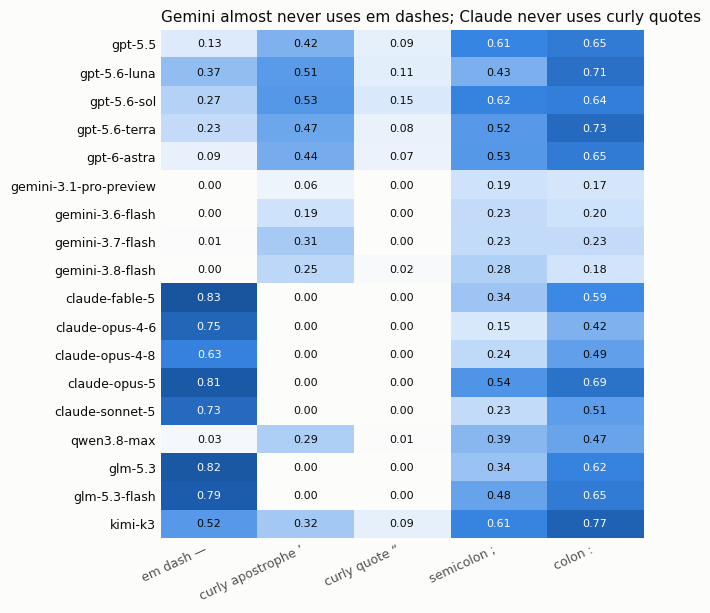

In [6]:
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "font.size": 9,
                     "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#0b0b0b"})
BLUES = plt.matplotlib.colors.LinearSegmentedColormap.from_list(
    "seq", ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])

MARKS = {"em dash —": "—", "curly apostrophe ’": "’", "curly quote “": "“", "semicolon ;": ";", "colon :": ":"}
rates = pd.DataFrame({name: train.groupby("model").text.apply(lambda s: s.str.contains(mark, regex=False).mean())
                      for name, mark in MARKS.items()}).loc[LABELS]

fig, ax = plt.subplots(figsize=(6.6, 6.2))
ax.imshow(rates.values, cmap=BLUES, vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(rates.shape[1]), rates.columns, rotation=25, ha="right")
ax.set_yticks(range(K), LABELS)
for (i, j), v in np.ndenumerate(rates.values):
    ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="#fcfcfb" if v > 0.55 else "#0b0b0b")
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Gemini almost never uses em dashes; Claude never uses curly quotes", loc="left", fontsize=11)
plt.tight_layout()
plt.show()

## 2. 검증: 반드시 프롬프트 단위로 나눕니다

테스트 프롬프트는 train에 없으므로 `prompt_id`로 묶어 폴드를 나눕니다. 일반 KFold는 낙관적인 것이 아니라 **오히려 크게 낮게** 나옵니다. 정답 지문은 검증 폴드에 있고 같은 프롬프트의 다른 모델 지문만 학습에 남아, 분류기가 같은 주제를 "정답이 아닌 모델"과 연결하기 때문으로 보입니다.

아래 셀은 이 차이를 작은 모델로 직접 확인합니다.

In [7]:
cv_folds = list(StratifiedGroupKFold(CFG["n_folds"], shuffle=True, random_state=CFG["seed"]).split(train, y, groups))
random_folds = list(StratifiedKFold(CFG["n_folds"], shuffle=True, random_state=CFG["seed"]).split(train, y))


def quick_cv(folds):
    X = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), sublinear_tf=True, min_df=2,
                        max_features=100_000, lowercase=False).fit_transform(train.text)
    pred = np.zeros(len(train), dtype=int)
    for a, b in folds:
        pred[b] = LinearSVC(C=0.3).fit(X[a], y[a]).predict(X[b])
    return balanced_accuracy_score(y, pred)


print(f"프롬프트 그룹 KFold BA: {quick_cv(cv_folds):.4f}")
print(f"일반 KFold BA        : {quick_cv(random_folds):.4f}")
print(f"무작위 추측 BA       : {1 / K:.4f}")

프롬프트 그룹 KFold BA: 0.3145
일반 KFold BA        : 0.1530
무작위 추측 BA       : 0.0556


## 3. n-gram 모델

주제 단어에 끌려가지 않도록, 같은 지문을 4가지로 바꿔 봅니다.

- **char**: 문자 3~5-gram. 문장부호와 철자 습관을 잡습니다.
- **word**: 단어와 문장부호의 1~2-gram.
- **shape**: 단어를 `x`/`X`로 치환한 글자 형태. 주제 정보가 거의 사라집니다.
- **func**: 기능어만 남기고 나머지는 `_`로 치환. 문장 구조만 남습니다.

벡터라이저는 라벨 없이 Open Pool에만 맞춰서, 검증 프롬프트의 정보가 들어가지 않게 했습니다. Open Pool의 `match_weight`는 풀의 문장부호 분포를 실제 지문에 맞추는 가중치입니다. 이 값은 train 전체로 계산됐기 때문에, CV 점수가 약간 높게 나올 수 있습니다.

In [8]:
FUNCTION_WORDS = set("""a an the and or but if while although because as so than that which who whom whose this these
those it its they them their he him his she her we us our you your i me my of in on at by for with from to into over
under about between through during not no nor is are was were be been being has have had do does did will would can
could may might must shall should very more most such only own same just also""".split())


def to_shape(s):
    return re.sub(r"[^\W\d_]+", lambda m: "X" if m[0].isupper() else "x", s)


def to_function(s):
    return " ".join(w.lower() if w.lower() in FUNCTION_WORDS or not w.isalnum() else "_"
                    for w in re.findall(r"\w+|[^\w\s]", s))


VIEWS = [
    ("char", None, dict(analyzer="char", ngram_range=(3, 5), max_features=250_000), 1.0),
    ("word", None, dict(analyzer="word", token_pattern=r"\w+|[^\w\s]", ngram_range=(1, 2), max_features=150_000), 0.7),
    ("shape", to_shape, dict(analyzer="char", ngram_range=(2, 6), max_features=60_000), 0.5),
    ("func", to_function, dict(analyzer="word", token_pattern=r"\S+", ngram_range=(1, 3), max_features=50_000), 0.5),
]


def sample_pool(n_per_label, seed=0):
    """라벨당 최대 n개를 match_weight에 비례해 비복원 추출합니다."""
    if pool is None:
        return None
    rng = np.random.default_rng(seed)
    picks = []
    for _, g in pool.groupby("model"):
        w = g.match_weight.fillna(0).to_numpy(dtype=float)
        k = min(n_per_label, int((w > 0).sum()))
        picks.append(g.index.to_numpy()[rng.choice(len(g), k, replace=False, p=w / w.sum())])
    return pool.loc[np.concatenate(picks)].reset_index(drop=True)


class MultiViewVectorizer:
    def __init__(self):
        self.parts = []

    @staticmethod
    def _prep(fn, texts):
        return [fn(t) for t in texts] if fn else list(texts)

    def fit_transform(self, texts):
        out = []
        for _, fn, opts, weight in VIEWS:
            v = TfidfVectorizer(lowercase=False, sublinear_tf=True, min_df=2, dtype=np.float32, **opts)
            out.append(v.fit_transform(self._prep(fn, texts)) * weight)
            self.parts.append((v, fn, weight))
        return sparse.hstack(out).tocsr()

    def transform(self, texts):
        return sparse.hstack([v.transform(self._prep(fn, texts)) * w for v, fn, w in self.parts]).tocsr()


ng_pool = sample_pool(CFG["ngram_pool_per_label"])
vectorizer = MultiViewVectorizer()
if ng_pool is not None:
    X_pool = vectorizer.fit_transform(ng_pool.text)
    y_pool = ng_pool.model.map(L2I).values
    X_train = vectorizer.transform(train.text)
else:
    X_train = vectorizer.fit_transform(train.text)
    X_pool, y_pool = None, None
X_test = vectorizer.transform(test.text)
print("특성 수:", X_train.shape[1], "|", elapsed())


def fit_svc(train_idx):
    Xs, ys, ws = [X_train[train_idx]], [y[train_idx]], [np.full(len(train_idx), CFG["ngram_train_weight"])]
    if X_pool is not None:
        Xs.append(X_pool); ys.append(y_pool); ws.append(np.ones(len(y_pool)))
    model = LinearSVC(C=CFG["svc_c"])
    model.fit(sparse.vstack(Xs).tocsr(), np.concatenate(ys), sample_weight=np.concatenate(ws))
    return model


oof_ng = np.zeros((len(train), K))
for fold, (a, b) in enumerate(cv_folds):
    oof_ng[b] = fit_svc(a).decision_function(X_train[b])
    print(f"fold {fold}: BA {balanced_accuracy_score(y[b], oof_ng[b].argmax(1)):.4f} | {elapsed()}")
print(f"n-gram OOF BA: {balanced_accuracy_score(y, oof_ng.argmax(1)):.4f}")

ng_test = fit_svc(np.arange(len(train))).decision_function(X_test)
del X_pool, ng_pool
gc.collect()

특성 수: 462293 | 2.6분
fold 0: BA 0.4593 | 3.9분
fold 1: BA 0.4907 | 5.2분
fold 2: BA 0.4870 | 6.4분
fold 3: BA 0.4595 | 7.7분
fold 4: BA 0.4370 | 9.0분
n-gram OOF BA: 0.4667


30

## 4. LoRA 분류기

공개 토론의 실험에 따르면 작성 스타일 정보는 Qwen3의 마지막 층보다 **앞쪽 층**에 더 많이 남아 있습니다. 그래서 앞쪽 `keep_layers`개 층만 쓰고, 여러 깊이의 은닉 상태를 평균 풀링해 이어 붙인 뒤 선형 분류합니다.

어텐션 투영층에는 LoRA를 답니다. 원래 가중치 \(W\)는 고정하고 저랭크 행렬만 학습합니다.

$$ \text{output} = Wx + \frac{\alpha}{r} B A x $$

\(B\)를 0으로 초기화하므로 학습 시작 시점의 출력은 원래 모델과 같습니다. 외부 패키지 없이 오프라인에서 돌도록 `peft` 없이 직접 구현했습니다.

학습은 두 단계입니다.
1. **Stage 1**: Open Pool로 각 모델의 전반적인 문체를 학습합니다.
2. **Stage 2**: 진짜 train 지문으로 미세 조정해 대회 데이터의 분포에 맞춥니다.

> **검증 상태:** 이 셀들은 작은 모델(Qwen3 0.6B, Mac MPS)로 코드가 끝까지 도는 것만 확인했습니다. 학습 성능과 T4 GPU에서의 시간, 메모리는 아직 확인하지 못했으므로 첫 실행 때 손실과 홀드아웃 점수를 확인하세요.

첫 번째 폴드의 프롬프트는 학습에서 빼고 홀드아웃으로 씁니다. 각 단계에는 시간 예산이 있어서, 예산이 다 되면 학습을 끊고 다음으로 넘어갑니다.

In [9]:
import torch
from torch import nn
from torch.nn import functional as F


def pick_device():
    if torch.cuda.is_available():
        return torch.device("cuda:0")
    if CFG["force_lora"] and torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def find_base_model():
    if os.environ.get("NTL_BASE_MODEL"):
        return os.environ["NTL_BASE_MODEL"]
    found = []
    for cfg_path in glob.glob(str(INPUT_ROOT / "**/config.json"), recursive=True):
        try:
            if json.load(open(cfg_path)).get("model_type") == "qwen3":
                found.append(str(Path(cfg_path).parent))
        except (OSError, ValueError):
            continue
    for wanted in CFG["base_preference"]:
        for path in found:
            if wanted in path:
                return path
    return found[0] if found else None


class LoRALinear(nn.Module):
    def __init__(self, base, r, alpha, dropout):
        super().__init__()
        self.base = base
        self.A = nn.Linear(base.in_features, r, bias=False)
        self.B = nn.Linear(r, base.out_features, bias=False)
        nn.init.kaiming_uniform_(self.A.weight, a=math.sqrt(5))
        nn.init.zeros_(self.B.weight)
        self.scale = alpha / r
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        delta = self.B(self.A(self.drop(x.to(self.A.weight.dtype))))
        return self.base(x) + (delta * self.scale).to(x.dtype)


def add_lora(trunk, targets=("q_proj", "k_proj", "v_proj", "o_proj")):
    for p in trunk.parameters():
        p.requires_grad_(False)
    n = 0
    for module in list(trunk.modules()):
        for name, child in list(module.named_children()):
            if name in targets and isinstance(child, nn.Linear):
                setattr(module, name, LoRALinear(child, CFG["lora_r"], CFG["lora_alpha"], CFG["lora_dropout"]))
                n += 1
    assert n > 0, "LoRA를 붙일 층을 찾지 못했습니다."
    return n


class StyleClassifier(nn.Module):
    def __init__(self, trunk, depths, n_classes, amp_dtype):
        super().__init__()
        self.trunk, self.depths, self.amp_dtype = trunk, depths, amp_dtype
        hidden = trunk.config.hidden_size
        self.norms = nn.ModuleList(nn.LayerNorm(hidden) for _ in depths)
        self.drop = nn.Dropout(0.1)
        self.head = nn.Linear(hidden * len(depths), n_classes)

    def forward(self, input_ids, attention_mask):
        with torch.autocast("cuda", dtype=self.amp_dtype, enabled=self.amp_dtype is not None):
            out = self.trunk(input_ids=input_ids, attention_mask=attention_mask,
                             output_hidden_states=True, use_cache=False)
        mask = attention_mask.unsqueeze(-1).float()
        feats = []
        for depth, norm in zip(self.depths, self.norms):
            pooled = (out.hidden_states[depth].float() * mask).sum(1) / mask.sum(1).clamp(min=1)
            feats.append(norm(pooled))
        return self.head(self.drop(torch.cat(feats, dim=-1)))


def build_classifier(base_dir, device):
    import transformers
    from transformers import AutoConfig, AutoModel, AutoTokenizer
    transformers.logging.set_verbosity_error()  # 잘라낸 층에 대한 로드 경고를 숨깁니다.
    tok = AutoTokenizer.from_pretrained(base_dir, padding_side="right")
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    mc = AutoConfig.from_pretrained(base_dir)
    keep = min(CFG["keep_layers"], mc.num_hidden_layers)
    mc.num_hidden_layers, mc.use_cache = keep, False
    if getattr(mc, "layer_types", None) is not None:
        mc.layer_types = mc.layer_types[:keep]
    if device.type == "cuda":
        # T4(compute capability 7.5)는 bf16 연산이 에뮬레이션이라 느리므로 fp16을 씁니다.
        weights = torch.bfloat16 if torch.cuda.get_device_capability(0)[0] >= 8 else torch.float16
        amp = weights
    else:
        weights, amp = torch.float32, None
    trunk = AutoModel.from_pretrained(base_dir, config=mc, dtype=weights)
    trunk.norm = nn.Identity()  # 마지막 정규화는 쓰지 않고 은닉 상태를 그대로 사용
    n_lora = add_lora(trunk)
    depths = [d for d in CFG["depths"] if d <= keep]
    model = StyleClassifier(trunk, depths, K, amp).to(device)
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"LoRA 층 {n_lora}개, 학습 파라미터 {trainable:,}개, 깊이 {depths}")
    return model, tok


def make_batches(lengths, batch_size, shuffle, seed=0):
    order = np.arange(len(lengths))
    if not shuffle:
        order = order[np.argsort(lengths)]
        return [order[i:i + batch_size] for i in range(0, len(order), batch_size)]
    rng = np.random.default_rng(seed)
    rng.shuffle(order)
    # 길이가 비슷한 지문끼리 묶어 패딩 낭비를 줄입니다.
    batches = []
    for i in range(0, len(order), batch_size * 50):
        chunk = order[i:i + batch_size * 50]
        chunk = chunk[np.argsort(lengths[chunk])]
        batches += [chunk[j:j + batch_size] for j in range(0, len(chunk), batch_size)]
    rng.shuffle(batches)
    return batches


def tokenize_all(tok, texts):
    enc = tok(list(texts), truncation=True, max_length=CFG["max_len"], add_special_tokens=False)["input_ids"]
    return [ids if ids else [tok.pad_token_id] for ids in enc]


def collate(ids_list, idx, pad_id, device):
    seqs = [ids_list[i] for i in idx]
    width = max(map(len, seqs))
    ids = torch.full((len(seqs), width), pad_id, dtype=torch.long)
    mask = torch.zeros((len(seqs), width), dtype=torch.long)
    for row, s in enumerate(seqs):
        ids[row, :len(s)] = torch.tensor(s)
        mask[row, :len(s)] = 1
    return ids.to(device), mask.to(device)


def train_stage(model, tok, device, texts, labels, epochs, lr, budget_h, name):
    params = [p for p in model.parameters() if p.requires_grad]
    head_params = list(model.head.parameters()) + list(model.norms.parameters())
    head_ids = {id(p) for p in head_params}
    optim = torch.optim.AdamW([{"params": [p for p in params if id(p) not in head_ids], "lr": lr},
                               {"params": head_params, "lr": lr * CFG["head_lr_mult"]}], weight_decay=0.01)
    ids_list = tokenize_all(tok, texts)
    lengths = np.array([len(s) for s in ids_list])
    n_steps = epochs * math.ceil(len(texts) / CFG["batch_size"])
    warmup = max(1, n_steps // 20)
    sched = torch.optim.lr_scheduler.LambdaLR(
        optim, lambda s: min(1, (s + 1) / warmup) * 0.5 * (1 + math.cos(math.pi * min(1, s / n_steps))))
    use_scaler = device.type == "cuda" and model.amp_dtype == torch.float16
    scaler = torch.amp.GradScaler("cuda", enabled=use_scaler)
    labels = torch.tensor(np.array(labels), dtype=torch.long)
    start, step, skipped, running = time.time(), 0, 0, 0.0
    model.train()
    for epoch in range(epochs):
        for batch in make_batches(lengths, CFG["batch_size"], True, seed=CFG["seed"] + epoch):
            if time.time() - start > budget_h * 3600:
                print(f"[{name}] 시간 예산 도달, {step}/{n_steps} 스텝에서 중단")
                model.eval()
                return
            ids, mask = collate(ids_list, batch, tok.pad_token_id, device)
            loss = F.cross_entropy(model(ids, mask), labels[batch].to(device), label_smoothing=0.05)
            optim.zero_grad(set_to_none=True)
            step += 1
            if not torch.isfinite(loss):
                skipped += 1
                continue
            scaler.scale(loss).backward()
            scaler.unscale_(optim)
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(optim)
            scaler.update()
            sched.step()
            running = 0.98 * running + 0.02 * loss.item() if step > 1 else loss.item()
            if step % max(1, n_steps // 10) == 0:
                print(f"[{name}] {step}/{n_steps} loss {running:.3f} | {(time.time() - start) / 60:.1f}분")
    print(f"[{name}] 완료: {step}스텝, 비정상 손실로 건너뜀 {skipped}회, {(time.time() - start) / 60:.1f}분")
    model.eval()


@torch.no_grad()
def predict_logits(model, tok, device, texts):
    model.eval()
    ids_list = tokenize_all(tok, texts)
    lengths = np.array([len(s) for s in ids_list])
    out = np.zeros((len(texts), K), dtype=np.float32)
    for batch in make_batches(lengths, CFG["batch_size"] * 2, False):
        ids, mask = collate(ids_list, batch, tok.pad_token_id, device)
        out[batch] = model(ids, mask).float().cpu().numpy()
    bad = ~np.isfinite(out).all(1)
    if bad.any():
        print(f"경고: 비정상 로짓 {bad.sum()}개는 0으로 대체합니다(이 지문은 n-gram 쪽 예측을 따릅니다).")
        out[bad] = 0
    return out


def trainable_state(model):
    keep = {n for n, p in model.named_parameters() if p.requires_grad}
    return {k: v.cpu() for k, v in model.state_dict().items() if k in keep}

In [10]:
holdout_idx = cv_folds[0][1]
fit_idx = cv_folds[0][0]
holdout_logits, lora_test = None, None
base_dir = find_base_model()
device = pick_device()
run_lora = CFG["use_lora"] and base_dir is not None and (device.type == "cuda" or CFG["force_lora"])
print(f"device={device}, base={base_dir}, LoRA 실행={run_lora}")

if run_lora:
    model, tok = build_classifier(base_dir, device)
    saved = find_optional("ntl_lora.pt")
    if saved is not None:
        ckpt = torch.load(saved, map_location="cpu", weights_only=True)
        missing = model.load_state_dict(ckpt["state"], strict=False)
        assert not missing.unexpected_keys, missing.unexpected_keys
        print("저장된 가중치를 사용합니다:", saved)
    else:
        lora_pool = sample_pool(CFG["lora_pool_per_label"], seed=CFG["seed"])
        if lora_pool is not None:
            train_stage(model, tok, device, lora_pool.text.tolist(), lora_pool.model.map(L2I).values,
                        CFG["stage1_epochs"], CFG["stage1_lr"], CFG["stage1_budget_h"], "stage1")
            print(f"stage1 홀드아웃 BA: {balanced_accuracy_score(y[holdout_idx], predict_logits(model, tok, device, train.text.values[holdout_idx]).argmax(1)):.4f}")
            del lora_pool
            gc.collect()
        train_stage(model, tok, device, train.text.values[fit_idx].tolist(), y[fit_idx],
                    CFG["stage2_epochs"], CFG["stage2_lr"], CFG["stage2_budget_h"], "stage2")
        torch.save({"state": trainable_state(model), "cfg": CFG, "labels": LABELS}, WORK_DIR / "ntl_lora.pt")

    holdout_logits = predict_logits(model, tok, device, train.text.values[holdout_idx])
    lora_test = predict_logits(model, tok, device, test.text.values)
    print(f"LoRA 홀드아웃 BA: {balanced_accuracy_score(y[holdout_idx], holdout_logits.argmax(1)):.4f} | {elapsed()}")
    del model
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()
else:
    print("LoRA를 건너뜁니다. GPU와 Qwen3 입력을 확인하세요. n-gram만으로 제출 파일을 만듭니다.")

device=cuda:0, base=/content/models/Qwen3-4B-Base, LoRA 실행=True


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

LoRA 층 72개, 학습 파라미터 6,256,658개, 깊이 [2, 4, 6, 9, 12, 15, 18]
[stage1] 562/5625 loss 2.395 | 3.0분
[stage1] 1124/5625 loss 2.128 | 6.1분
[stage1] 1686/5625 loss 1.976 | 9.1분
[stage1] 2248/5625 loss 1.841 | 12.3분
[stage1] 2810/5625 loss 1.856 | 15.4분
[stage1] 3372/5625 loss 1.677 | 18.5분
[stage1] 3934/5625 loss 1.697 | 21.7분
[stage1] 4496/5625 loss 1.575 | 24.8분
[stage1] 5058/5625 loss 1.560 | 27.9분
[stage1] 5620/5625 loss 1.444 | 31.0분
[stage1] 완료: 5625스텝, 비정상 손실로 건너뜀 0회, 31.0분
stage1 홀드아웃 BA: 0.4889
[stage2] 54/540 loss 1.639 | 0.3분
[stage2] 108/540 loss 1.583 | 0.6분
[stage2] 162/540 loss 1.575 | 0.9분
[stage2] 216/540 loss 1.559 | 1.2분
[stage2] 270/540 loss 1.537 | 1.5분
[stage2] 324/540 loss 1.402 | 1.8분
[stage2] 378/540 loss 1.301 | 2.2분
[stage2] 432/540 loss 1.296 | 2.5분
[stage2] 486/540 loss 1.323 | 2.8분
[stage2] 540/540 loss 1.328 | 3.1분
[stage2] 완료: 540스텝, 비정상 손실로 건너뜀 0회, 3.1분
LoRA 홀드아웃 BA: 0.5204 | 45.0분


## 5. 블렌딩

두 모델의 점수를 각각 온도 조정한 로그 확률로 바꾼 뒤 가중합합니다. 온도와 가중치는 LoRA 학습에 쓰지 않은 홀드아웃 프롬프트에서 고릅니다. 다만 같은 데이터로 가중치를 고르므로 블렌드의 홀드아웃 점수는 다소 낙관적입니다.

In [11]:
def log_softmax_np(x, temperature=1.0):
    x = x / temperature
    x = x - x.max(1, keepdims=True)
    return x - np.log(np.exp(x).sum(1, keepdims=True))


def best_temperature(scores, labels, grid=(0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1, 1.5, 2, 3)):
    nll = [-log_softmax_np(scores, t)[np.arange(len(labels)), labels].mean() for t in grid]
    return grid[int(np.argmin(nll))]


T_NG = best_temperature(oof_ng, y)
ng_oof_lp, ng_test_lp = log_softmax_np(oof_ng, T_NG), log_softmax_np(ng_test, T_NG)
print("n-gram 온도:", T_NG)

blend_w = 0.0
if holdout_logits is not None:
    T_LORA = best_temperature(holdout_logits, y[holdout_idx])
    lora_lp = log_softmax_np(holdout_logits, T_LORA)
    table = {w: balanced_accuracy_score(y[holdout_idx], (w * lora_lp + (1 - w) * ng_oof_lp[holdout_idx]).argmax(1))
             for w in (i / 10 for i in range(11))}
    blend_w = max(table, key=table.get)
    print("LoRA 가중치별 홀드아웃 BA:", {k: round(float(v), 4) for k, v in table.items()})
    print(f"선택한 LoRA 가중치: {blend_w}")
    test_lp = blend_w * log_softmax_np(lora_test, T_LORA) + (1 - blend_w) * ng_test_lp
    blend_holdout = blend_w * lora_lp + (1 - blend_w) * ng_oof_lp[holdout_idx]
    eval_idx, eval_lp = holdout_idx, blend_holdout
else:
    test_lp = ng_test_lp
    eval_idx, eval_lp = np.arange(len(train)), ng_oof_lp

print(f"최종 검증 BA (n={len(eval_idx)}): {balanced_accuracy_score(y[eval_idx], eval_lp.argmax(1)):.4f}")

n-gram 온도: 0.2
LoRA 가중치별 홀드아웃 BA: {0.0: 0.4593, 0.1: 0.4796, 0.2: 0.4926, 0.3: 0.5148, 0.4: 0.5315, 0.5: 0.5426, 0.6: 0.5315, 0.7: 0.5315, 0.8: 0.5278, 0.9: 0.5352, 1.0: 0.5204}
선택한 LoRA 가중치: 0.5
최종 검증 BA (n=540): 0.5426


### 어디서 틀리는가

왼쪽은 모델별 recall, 오른쪽은 혼동 행렬입니다. 행이 정답, 열이 예측이고 각 행의 합은 1입니다.

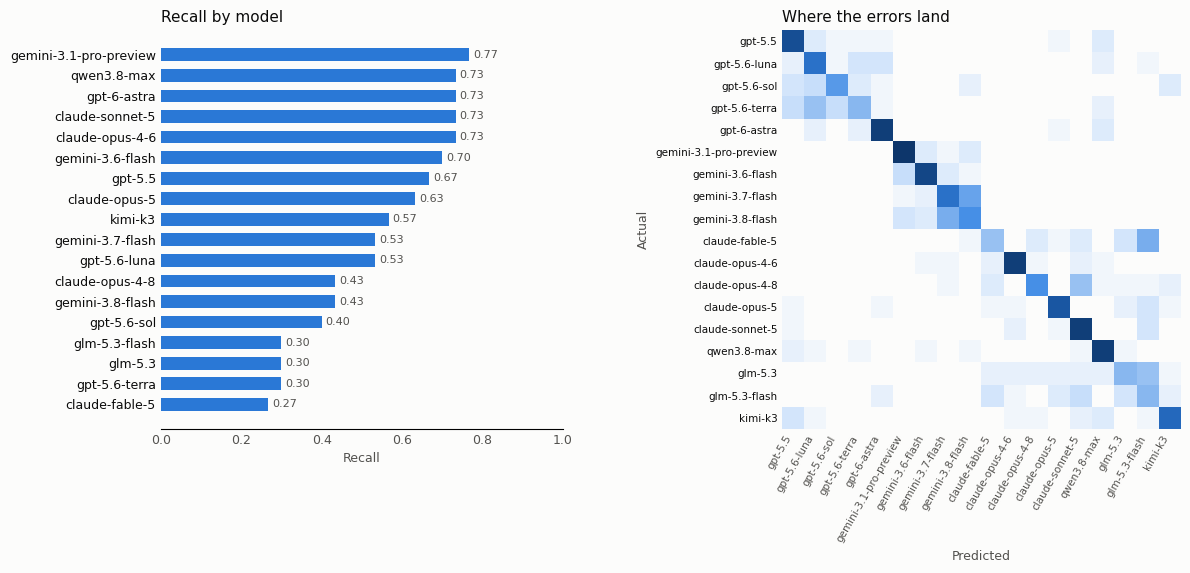

오답 중 같은 연구소 모델로 틀린 비율: 56.7%


In [12]:
pred_eval = eval_lp.argmax(1)
cm = confusion_matrix(y[eval_idx], pred_eval, labels=range(K), normalize="true")
recall = pd.Series(np.diag(cm), index=LABELS)
order = recall.sort_values().index

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.8), width_ratios=[1, 1.5])
ax1.barh(range(K), recall[order], color="#2a78d6", height=0.62)
ax1.set_yticks(range(K), order)
for i, v in enumerate(recall[order]):
    ax1.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=8, color="#52514e")
ax1.set_xlim(0, 1)
ax1.set_xlabel("Recall")
ax1.set_title("Recall by model", loc="left", fontsize=11)
for s in ("top", "right", "left"):
    ax1.spines[s].set_visible(False)
ax1.tick_params(length=0)

ax2.imshow(cm, cmap=BLUES, vmin=0, vmax=max(0.6, cm.max()))
ax2.set_xticks(range(K), LABELS, rotation=60, ha="right", fontsize=7.5)
ax2.set_yticks(range(K), LABELS, fontsize=7.5)
ax2.set_xlabel("Predicted")
ax2.set_ylabel("Actual")
ax2.tick_params(length=0)
for s in ax2.spines.values():
    s.set_visible(False)
ax2.set_title("Where the errors land", loc="left", fontsize=11)
plt.tight_layout()
plt.show()

same_lab = lambda a, b: a.split("-")[0].rstrip("0123456789.") == b.split("-")[0].rstrip("0123456789.")
wrong = pred_eval != y[eval_idx]
within = np.mean([same_lab(LABELS[t], LABELS[p]) for t, p in zip(y[eval_idx][wrong], pred_eval[wrong])])
print(f"오답 중 같은 연구소 모델로 틀린 비율: {within:.1%}")

## 6. 프롬프트 중심화 (테스트 내부 관계 활용)

같은 프롬프트에 답한 지문들은 주제를 공유합니다. 그 묶음의 평균 점수를 빼면 주제 신호가 줄고 문체 차이가 남습니다. 테스트에는 `prompt_id`가 없으므로 주제 단어 TF-IDF로 지문을 묶습니다. 대회 주최 측은 테스트 지문 간 관계를 활용해도 된다고 토론에서 답했습니다.

n-gram OOF로 시뮬레이션한 결과입니다(Open Pool 라벨당 1,000개, 중심화 강도 0.5, 묶음 거리 0.9, 5회 평균).

| 프롬프트당 지문 수 | 중심화 전 | 중심화 후 |
|---|---|---|
| 1 | 0.429 | 0.420 |
| 2 | 0.450 | 0.453 |
| 4 | 0.428 | 0.451 |
| 8 | 0.432 | 0.461 |

프롬프트당 지문이 1개뿐이면 오히려 손해입니다. 실제 테스트 구성은 공개되지 않았고, LoRA 블렌드에서는 측정하지 않았습니다.

묶음 크기가 2~18일 때만 적용합니다. 인터랙티브 실행(테스트 3행)에서는 묶음이 생기지 않아 아무 변화가 없습니다.

In [13]:
def topic_clusters(texts, distance):
    if len(texts) < 2:
        return np.zeros(len(texts), dtype=int)
    X = TfidfVectorizer(stop_words="english", sublinear_tf=True, dtype=np.float32).fit_transform(texts).toarray()
    return AgglomerativeClustering(n_clusters=None, metric="cosine", linkage="average",
                                   distance_threshold=distance).fit_predict(X)


def center_by_cluster(lp, clusters, strength):
    out = lp.copy()
    for c in np.unique(clusters):
        idx = np.where(clusters == c)[0]
        if 2 <= len(idx) <= 18:
            out[idx] = lp[idx] - strength * lp[idx].mean(0)
    return out


final_lp = test_lp
if CFG["use_centering"]:
    clusters = topic_clusters(test.text.tolist(), CFG["cluster_distance"])
    sizes = pd.Series(clusters).value_counts()
    print(f"테스트 묶음 {len(sizes)}개, 중심화 대상 지문 {sizes[(sizes >= 2) & (sizes <= 18)].sum()}개 / {len(test)}개")
    final_lp = center_by_cluster(test_lp, clusters, CFG["center_strength"])

테스트 묶음 3개, 중심화 대상 지문 0개 / 3개


## 7. 제출 파일

In [14]:
submission = pd.DataFrame({"id": test["id"].values, "model": [LABELS[i] for i in final_lp.argmax(1)]})
assert submission["id"].is_unique and submission.notna().all().all()
assert set(submission["id"]) == set(test["id"]) and submission.model.isin(LABELS).all()
submission.to_parquet(WORK_DIR / "submission.parquet", index=False)
print(submission.model.value_counts().to_string())
print(f"submission.parquet 저장 완료: {submission.shape} | 총 {elapsed()}")
submission.head()

model
claude-sonnet-5           1
gpt-5.6-terra             1
gemini-3.1-pro-preview    1
submission.parquet 저장 완료: (3, 2) | 총 45.0분


,id,model
0,00353fb1c541,claude-sonnet-5
1,005f5a9a6139,gpt-5.6-terra
2,0062a53d5487,gemini-3.1-pro-preview


In [15]:
# Colab 전용: 결과 파일을 Google Drive로 복사 (Kaggle에서는 건너뜀)
import shutil
if os.path.exists("/content/drive/MyDrive") and "KAGGLE_KERNEL_RUN_TYPE" not in os.environ:
    dest = Path("/content/drive/MyDrive/ntl")
    dest.mkdir(parents=True, exist_ok=True)
    for f in sorted(WORK_DIR.glob("*")):
        if f.is_file():
            shutil.copy2(f, dest / f.name)
            print(f"복사: {f.name} ({f.stat().st_size / 1e6:.1f}MB) -> {dest}")

복사: ntl_lora.pt (25.1MB) -> /content/drive/MyDrive/ntl
복사: submission.parquet (0.0MB) -> /content/drive/MyDrive/ntl
